# BÁO CÁO PHẦN 1 - BÀI 2 (TRANG 15-17): TITANIC DATASET
## CÂU 4: Khảo sát sự liên quan giữa Cổng lên tàu (embarked) và Loại vé (pclass) với Khả năng sống sót (survived) phân biệt theo Giới tính (sex)
- Vẽ đồ thị pointplot kết hợp FacetGrid theo cổng lên tàu và hạng vé
- Vẽ biểu đồ barplot tỷ lệ sống sót theo hạng vé
- Khảo sát phân bố tuổi theo hạng vé và sống sót


Họ tên: Hoàng Thành Đạt - MSSV: 6451071016


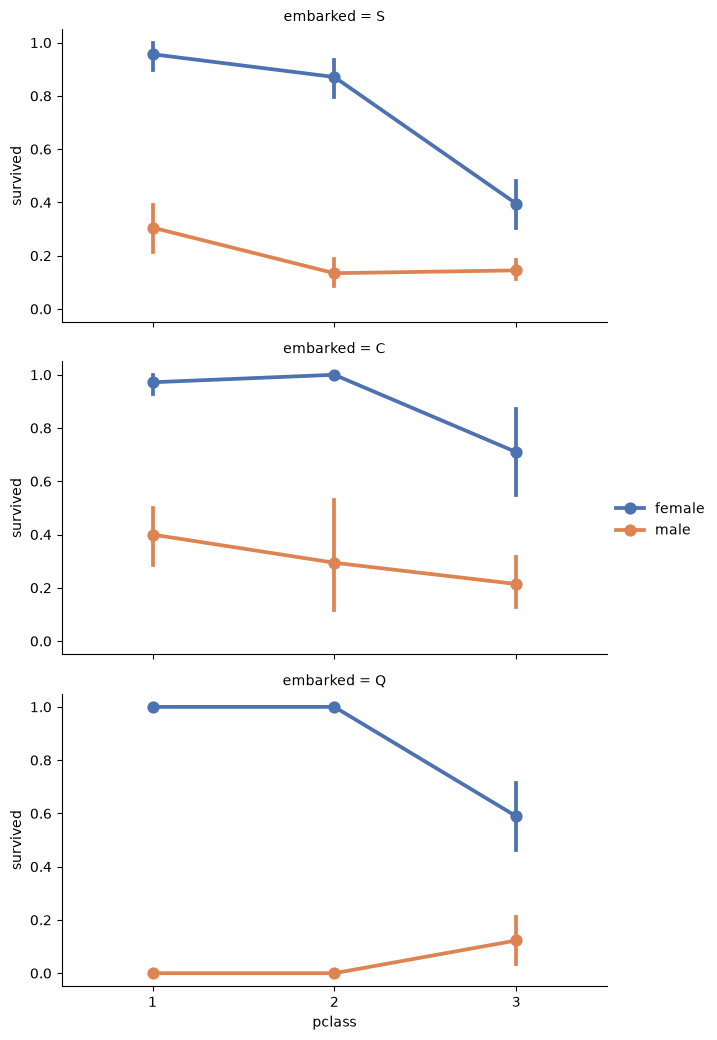

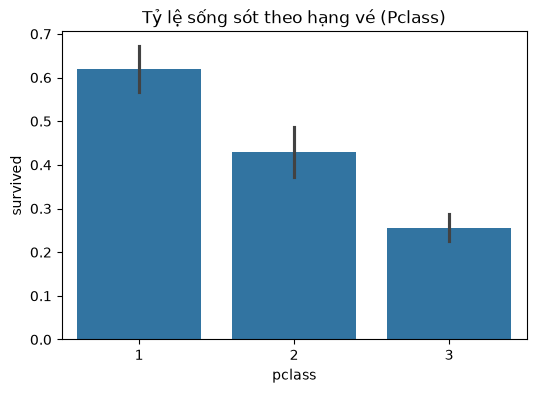

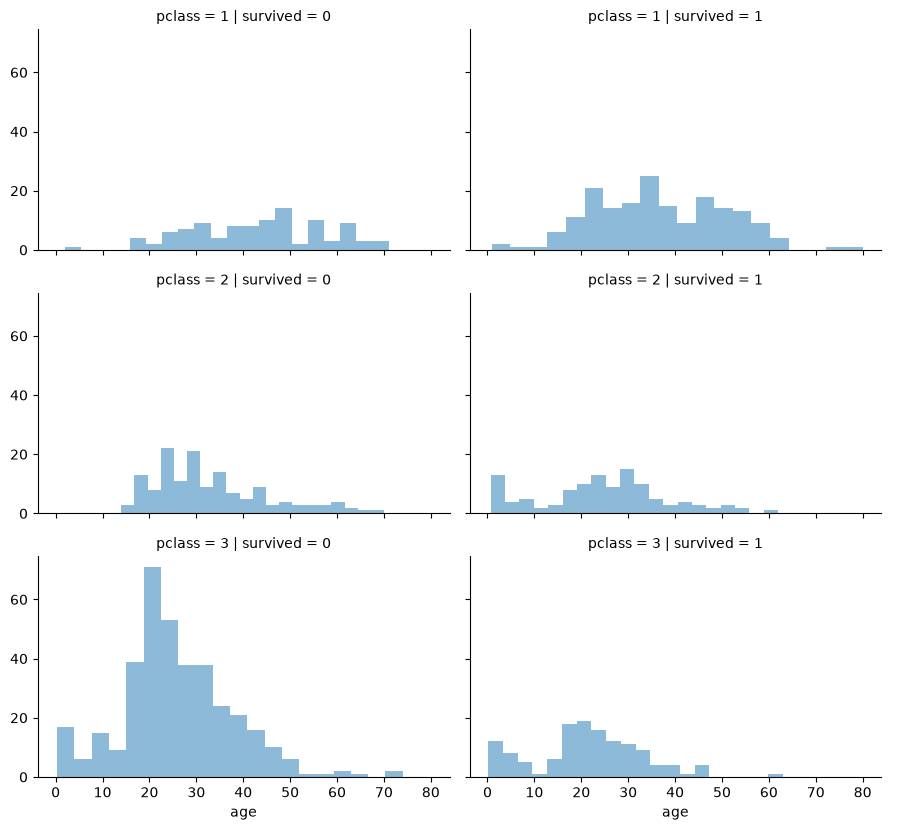

In [1]:
# ==========================================
# THÔNG TIN SINH VIÊN THỰC HIỆN
# Họ và tên: Hoàng Thành Đạt
# MSSV: 6451071016
# ==========================================
ho_ten = "Hoàng Thành Đạt"
mssv = "6451071016"
print(f"Họ tên: {ho_ten} - MSSV: {mssv}")

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def get_data_path(rel_filename):
    for candidate in [
        os.path.join("..", "..", "dataset", rel_filename),
        os.path.join("..", "dataset", rel_filename),
        os.path.join("dataset", rel_filename),
        rel_filename
    ]:
        if os.path.exists(candidate):
            return candidate
    return rel_filename


path = get_data_path('titanic.csv')
with open(path) as f:
    df = pd.read_csv(f, dtype={'age': np.float64, 'sibsp': np.int64, 'parch': np.int64})

# Đồ thị 1: Cổng lên tàu (embarked) và loại vé (pclass) với sống sót, phân theo giới tính
FacetGrid = sns.FacetGrid(df, row='embarked', height=3.5, aspect=1.8)
FacetGrid.map(sns.pointplot, 'pclass', 'survived', 'sex', palette='deep', order=[1, 2, 3], hue_order=['female', 'male'])
FacetGrid.add_legend()
plt.show()

# Đồ thị 2: Tỷ lệ sống sót theo loại vé pclass
plt.figure(figsize=(6, 4))
sns.barplot(x='pclass', y='survived', data=df)
plt.title("Tỷ lệ sống sót theo hạng vé (Pclass)")
plt.show()

# Đồ thị 3: Phân bố tuổi theo Pclass và Survived
grid = sns.FacetGrid(df, col='survived', row='pclass', height=2.8, aspect=1.6)
grid.map(plt.hist, 'age', alpha=.5, bins=20)
grid.add_legend()
plt.show()


### Nhận xét Câu 4:
- Thuộc tính Cổng lên tàu (`embarked`) liên quan đến khả năng sống sót và phụ thuộc vào giới tính:
  * Phụ nữ lên tàu ở cổng Q và S có tỷ lệ sống rất cao (> 90% ở vé hạng 1 và 2), lên ở cổng C tỷ lệ chết cao hơn một chút.
  * Ngược lại, nam giới lên ở cổng C có tỷ lệ sống sót cao hơn so với cổng Q và S.
- Loại vé (`pclass`) ảnh hưởng rất rõ rệt đến cơ hội sống:
  * Khách vé hạng 1 có tỷ lệ sống cao nhất (> 60%).
  * Khách vé hạng 3 có tỷ lệ sống thấp nhất (~ 25%), đặc biệt hành khách nam trẻ tuổi ở hạng 3 có số lượng tử vong đông nhất.
